# 1. Introduction
# From a promising score to an experiment we can explain and rebuild

We use hospital-death prediction to follow one story: **the random forest scores better than logistic regression on validation, but how dependable is that lead, how does it make predictions, and can we reproduce the result?**

**Trace the data → Compare models → Check the lead → Explain predictions → Challenge the explanation → Tune and save**

The saved analysis gives a qualified answer. The forest leads on all five shared development splits, but the margin varies. Tree probabilities expose the calculation, and SHapley Additive exPlanations (SHAP) assigns input contributions. Tuning adds only a small selected validation gain, and the complete final pipeline can be reloaded and rebuilt

**Where W&B fits:** Python fits the models and calculates their explanations. Weights & Biases (W&B) records each experiment, compares its settings and results, organises repeated fits, coordinates the sweep and connects versioned inputs to the saved model. It is the record that lets us move between a number, its explanation and the experiment that produced it

The data contain 4,000 intensive care unit (ICU) stays from [PhysioNet Challenge 2012, set A](https://physionet.org/content/challenge-2012/1.0.0/). The target is death before hospital discharge. Inputs summarise the first 48 h, so prediction occurs after that observation window, not at admission. The source cohort excludes stays shorter than 48 h

This is a completed classroom walkthrough. Figures and interpretations describe the recorded run. The added comparison figures reuse those recorded results; a fresh online execution records the updated figures in its own runs. The optional surrogate was disabled

Notebooks 01 to 03 cover survival analysis, Cox models, trees and forests. This notebook concentrates on tracking and understanding this binary classifier. Checks on other models in those notebooks or the Responsible Artificial Intelligence (RAI) notebook do not validate this model

> Connect each result to its experiment, then check its stability, explanation and reproducibility


# 2. Setup

The completed analysis uses the `icu-survival` Python environment from `environment.yml`. Shared functions come from `utils.py`, and the data file `PhysionetChallenge2012-set-a.csv.gz` is in the same folder

The main split and model fits use seed 42. Library versions are recorded because software changes can affect results. Saving the notebook before execution allows the logged source to match the code being run

- **Online:** runs, plots and artifacts are uploaded to the selected W&B project using the saved login
- **Offline:** `WANDB_MODE = "offline"` stores runs locally and skips the online sweep and Registry steps
- **Optional surrogate:** `RUN_SURROGATE = False` leaves the smaller imitation tree disabled in this saved analysis
- **Registry:** the empty `REGISTRY_TARGET` skips linking the final model to a Registry collection

Tracking files are stored locally outside OneDrive to avoid sync interruptions. The saved pipeline and settings remain in `tmp/wandb_outputs`. A fresh run with a different execution mode requires restarting the kernel and running from the top


In [1]:
# Setup: imports, reproducibility and shared helpers
from pathlib import Path
from functools import partial
from importlib.metadata import version
from sklearn.base import clone
import hashlib
import json
import os
import sys
import random
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import joblib
from IPython.display import display, Markdown

import wandb
from wandb import Api as WandbApi

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import PartialDependenceDisplay
from sklearn.metrics import roc_auc_score, average_precision_score, r2_score

from utils import (
    WandbRunContext, start_run, score, log_curves, log_top_bar, log_fig,
    rf_shap, make_split, make_preprocessor, prepare, split_manifest,
    run_baseline, perm_drop, train_rf_sweep,
    display_details_table, plot_patient_split, plot_baseline_comparison,
    plot_variance_comparison, plot_sanity_comparison, sweep_results_frame,
    plot_sweep_tradeoff, plot_reproducibility_chain,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

WB_PROJECT = "ml-healthcare-intro"
DATA_ARTIFACT = "physionet2012-set-a"   # versioned dataset (section 4)
SPLIT_ARTIFACT = "icu-split-manifest"   # which patient is in train, validation or test (section 4)

# Random Forest settings used as the baseline in sections 5 to 8 (the sweep in section 9 tunes them)
RF_PARAMS = dict(n_estimators=300, max_depth=None, max_features="sqrt", min_samples_leaf=5)

# Choose the session route here, before starting runs
WANDB_MODE = os.environ.get("WANDB_MODE", "online")  # "offline" if you have no account or internet
RUN_SURROGATE = False  # optional surrogate exercise (section 8.3)
REGISTRY_TARGET = ""  # copy the exact path: wandb-registry-<registry name>/<collection name>
NOTEBOOK = Path("04_ICU_ML_W&B.ipynb")
OUTPUT_DIR = Path("tmp/wandb_outputs")  # ignored by git
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
# Keep run staging outside OneDrive to avoid sync interruptions during code capture
TRACKING_DIR = Path(os.environ.get("LOCALAPPDATA", tempfile.gettempdir())) / "ICU_Survival_analysis" / "wandb_tracking"
TRACKING_DIR.mkdir(parents=True, exist_ok=True)
os.environ["WANDB_MODE"] = WANDB_MODE
os.environ.setdefault("WANDB_SILENT", "true")
os.environ["WANDB_DIR"] = str(TRACKING_DIR.resolve())
VERSIONS = {p: version(p) for p in ["numpy", "pandas", "scipy", "scikit-learn", "shap", "wandb", "joblib"]}
ENVIRONMENT = {"python": sys.version.split()[0], **VERSIONS}
INPUT_REFS = []
WB_ENTITY = None  # W&B account of this experiment, stored by the first run (section 4)
DATA_REF = None
DATA_SHA256 = None
SPLIT_SHA256 = None
print("Execution mode:", WANDB_MODE, "| Optional surrogate:", RUN_SURROGATE)
print("Local tracking folder:", TRACKING_DIR.resolve())
display_details_table(pd.Series(ENVIRONMENT, name="version").to_frame(), "Recorded software versions")
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

Execution mode: online | Optional surrogate: False
Local tracking folder: C:\Users\idiaz\AppData\Local\ICU_Survival_analysis\wandb_tracking


,version
python,3.11.17
numpy,2.4.6
pandas,2.3.3
scipy,1.17.1
scikit-learn,1.9.1
shap,0.51.0
wandb,0.30.0
joblib,1.6.0


In [2]:
# Bind the shared tracking settings; implementations live in utils.py
run_context = WandbRunContext(
    project=WB_PROJECT, environment=ENVIRONMENT, optional_surrogate=RUN_SURROGATE,
    seed=SEED, notebook=NOTEBOOK, mode=WANDB_MODE,
)
start_run = partial(start_run, context=run_context)


# 3. What W&B does in this analysis

Every tracked experiment follows the same pattern: `start_run` records its settings and inputs, the model is fitted locally, `wandb.log` records results, and `run.finish()` completes that run. Shared implementations live in `utils.py`

| Point in the story | W&B contribution | Where the evidence appears |
|---|---|---|
| Establish fair inputs | Versions the dataset and patient split | Artifacts and their version labels |
| Compare baselines | Records one run per model with the same metrics | Runs table, tag `baseline` |
| Check repeatability | Groups runs by the source of randomness | Groups `rf-variance-model_seed` and `rf-variance-data_split` |
| Explain the forest | Stores prediction tables, paths and explanation plots | Runs `04-inside-the-forest` and `05-explanations` |
| Challenge the ranking | Keeps shuffled-label results beside the real model's evidence | Run `07-explanation-sanity-check` |
| Tune and reproduce | Coordinates trial settings, retrieves scores and versions the final pipeline | Sweeps, final-run configuration and artifact Lineage |

The charts below make the same evidence visible inside the notebook. The W&B website provides comparison and filtering across runs and tables. SHAP figures and forest diagrams are logged images; W&B does not calculate new SHAP values when a plot is opened

The default repetition checks use five fits per source. The sweep requests ten trials and comparisons use completed, scored trials. An alias such as `staging` is a label, not clinical approval; Registry linking was skipped in the recorded run

References: [experiment tracking](https://docs.coreweave.com/products/wandb/track), [sweeps](https://docs.coreweave.com/products/wandb/sweeps)


In [3]:
if WANDB_MODE == "online":
    wandb.login()  # use the secure prompt; never paste a key into a notebook cell
else:
    print("Offline: runs stay under", TRACKING_DIR.resolve())

# 4. Version the data and patient splits

A score needs a traceable source. This run records the raw data and a **split manifest**, a file listing each stay and its role: train, validation or test

The split uses 60% of stays for training, 20% for validation and 20% for the final test. Section 6 reshuffles only the first two groups. The test patients remain fixed

Missing inputs are filled using training medians. `recordid` identifies stays and is not a predictor. `Survival` and `Length_of_stay` describe later outcomes and are removed

The source uses `-1` for unknown values. These codes become missing inputs before the imputer is fitted. Otherwise an unknown severity score of -1 would be treated as a real measurement

**Names that appear in the outputs:** Simplified Acute Physiology Score I (`SAPS-I`) and Sequential Organ Failure Assessment (`SOFA`) summarise illness severity. Other shortened feature names follow the [source data dictionary](https://physionet.org/content/challenge-2012/1.0.0/)

| Feature family | Plain meaning |
|---|---|
| `GCS` | Glasgow Coma Scale, a responsiveness score |
| `BUN` | Blood urea nitrogen, a kidney-related blood test |
| `ALP` | Alkaline phosphatase, a blood enzyme measurement |
| `WBC`, `HCT` | White blood cell count and haematocrit |
| `HR`, `NISysABP` | Heart rate and non-invasive systolic blood pressure |
| `PaO2` | Arterial oxygen partial pressure |
| `MechVent`, `Temp` | Mechanical ventilation and temperature |

`first`, `last`, `highest`, `lowest` and `median` name summaries of recorded measurements. The plots retain the source values so their inputs match the model; these names describe measurements, not diagnoses

**W&B evidence:** run `01-data-and-splits` logs the raw-data artifact and the split-manifest artifact. Later model runs declare these versions as inputs, so their data source and test patients can be traced rather than inferred from a score


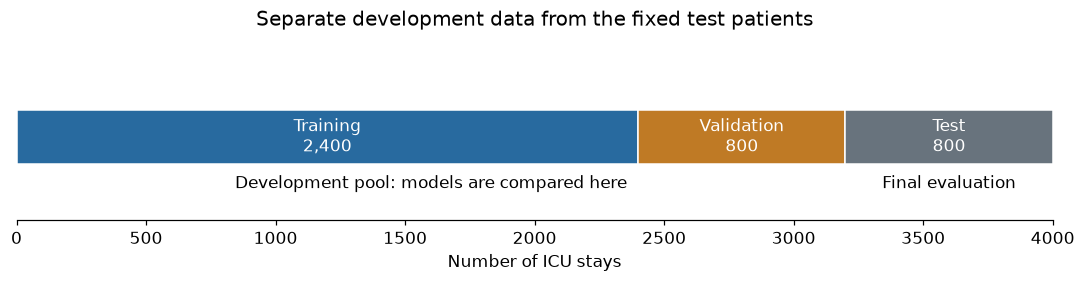

Predictors contain 334 missing-value codes (-1); preprocessing converts these to NaN
Pinned input versions: ['idiazl/ml-healthcare-intro/physionet2012-set-a:v0', 'idiazl/ml-healthcare-intro/icu-split-manifest:v0']
Run URL: https://wandb.ai/idiazl/ml-healthcare-intro/runs/zshct07o
4000 stays, 116 features, death rate 0.139
Train 2400, validation 800, test 800


In [4]:
PATH = "PhysionetChallenge2012-set-a.csv.gz"
if not os.path.exists(PATH):
    raise FileNotFoundError(f"Data file not found at '{PATH}'. Place it next to this notebook")
ICU = pd.read_csv(PATH, compression="gzip")

TARGET = "In-hospital_death"
ID_COL = "recordid"
LEAKAGE_COLS = ["Survival", "Length_of_stay"]  # known only at the end of the stay
assert ICU[ID_COL].notna().all() and ICU[ID_COL].is_unique, "Each ICU stay needs one unique ID"
assert ICU[TARGET].notna().all() and ICU[TARGET].isin([0, 1]).all(), "Check outcome labels"
ICU[TARGET] = ICU[TARGET].astype(int)
DATA_SHA256 = hashlib.sha256(Path(PATH).read_bytes()).hexdigest()
run_context.dataset_sha256 = DATA_SHA256
run = start_run("01-data-and-splits", "data", config={"dataset_sha256": DATA_SHA256}, inputs=False)
WB_ENTITY = run.entity  # reused in section 10, so the sweep is read from the same account

X = ICU.drop(columns=[c for c in [TARGET, ID_COL, *LEAKAGE_COLS] if c in ICU.columns])
# PhysioNet uses -1 for missing or unknown values; valid source inputs are nonnegative
source_missing = int(X.eq(-1).sum().sum())
print(f"Predictors contain {source_missing} missing-value codes (-1); preprocessing converts these to NaN")
y = ICU[TARGET]
cat_cols = [c for c in X.columns if X[c].dtype == "object"]
num_cols = [c for c in X.columns if c not in cat_cols]

# Basic facts, logged to the run summary
miss = X.replace(-1, np.nan).isna().mean().sort_values(ascending=False)
wandb.log({"dataset_rows": len(ICU), "n_features": X.shape[1], "positive_rate": float(y.mean())})
log_top_bar(miss.rename("missing_fraction").rename_axis("column").reset_index(),
            "column", "missing_fraction", "missingness_top15_chart", "Fraction missing (top 15)")

# Version the raw file
data_at = wandb.Artifact(DATA_ARTIFACT, type="dataset",
                         description="PhysioNet Challenge 2012 set A, one row per ICU stay (first 48 h summaries)",
                         metadata={"rows": len(ICU), "positive_rate": float(y.mean()), "target": TARGET})
data_at.add_file(PATH)
logged_data = run.log_artifact(data_at)

# Set aside test once. Later repetitions use only the development pool
idx_dev, idx_test = train_test_split(ICU.index, test_size=0.2, stratify=y, random_state=SEED)

idx_train, idx_val, idx_test = make_split(SEED, idx_dev=idx_dev, idx_test=idx_test, y=y)
preprocessor = make_preprocessor(num_cols, cat_cols)
X_train_t = preprocessor.fit_transform(X.loc[idx_train])
X_val_t = preprocessor.transform(X.loc[idx_val])
y_train, y_val = y.loc[idx_train], y.loc[idx_val]
feat_names = list(X_train_t.columns)

# Version the split: anyone can rebuild the same train, validation and test patients
manifest = split_manifest(idx_train, idx_val, idx_test, ICU=ICU, id_col=ID_COL)
manifest_file = OUTPUT_DIR / f"split_manifest_seed{SEED}.csv"
manifest.to_csv(manifest_file, index=False)
SPLIT_SHA256 = hashlib.sha256(manifest_file.read_bytes()).hexdigest()
run_context.split_sha256 = SPLIT_SHA256
run.config.update({"main_split_sha256": SPLIT_SHA256}, allow_val_change=True)
split_at = wandb.Artifact(SPLIT_ARTIFACT, type="split", description="Patient-level 60/20/20 stratified split",
                          metadata={"seed": SEED, **manifest["split"].value_counts().to_dict()})
split_at.add_file(str(manifest_file))
logged_split = run.log_artifact(split_at)
if WANDB_MODE == "online":
    logged_data.wait()
    logged_split.wait()
    DATA_REF = logged_data.qualified_name
    INPUT_REFS = [DATA_REF, logged_split.qualified_name]
    run_context.input_refs = INPUT_REFS
    print("Pinned input versions:", INPUT_REFS)
wandb.log({"train_rows": len(idx_train), "val_rows": len(idx_val), "test_rows": len(idx_test)})

log_fig("patient_split", plot_patient_split(len(idx_train), len(idx_val), len(idx_test)), tight=False)

print(f"Run URL: {run.url if WANDB_MODE == 'online' else 'offline'}")
print(f"{len(ICU)} stays, {X.shape[1]} features, death rate {y.mean():.3f}")
print(f"Train {len(idx_train)}, validation {len(idx_val)}, test {len(idx_test)}")
run.finish()

### What the data and split results show

- **Population:** 4,000 stays and 116 predictor columns, with an overall death rate of 13.9%
- **Missing inputs:** 334 predictor values use the source code -1; preprocessing converts them to missing values before imputation
- **Patient split:** 2,400 stays train the models, 800 validate them and 800 remain reserved for final testing
- **Traceability:** the saved run pins dataset `physionet2012-set-a:v0` and split manifest `icu-split-manifest:v0`

A version identifies the file content used by this experiment. Later runs can have different version numbers. The saved source, data checksum and split checksum provide further checks on reproducibility

> Save data versions and patient splits so every model comparison uses a traceable population

**Reading the visual:** training and validation form the development pool. The grey test block stays outside the model comparisons and tuning. This separation is what makes the final test result meaningful


# 5. Compare three tracked baselines

With the patient split fixed, we fit logistic regression (LR), a shallow decision tree (DT) and a random forest (RF) on the same training patients and evaluate them on the same validation patients. Each has its own W&B run, connecting its scores to its settings

| Logged metric | Meaning | Better direction |
|---|---|---|
| `val_auc` | Area under the receiver operating characteristic curve (AUROC): how well deaths rank above survivors | Higher; chance ranking is 0.5 |
| `val_pr` | Average precision, used here to summarise the precision-recall curve | Higher; compare with this validation set's death rate |
| `val_brier` | Mean squared error between predicted probability and outcome, 0 or 1 | Lower |
| `val_ece` | Expected calibration error (ECE): weighted average gap between predicted and observed rates in up to 10 equal-count bins | Lower; depends on the chosen bins |

The label **AUPRC** means area under the precision-recall curve. Here it refers to scikit-learn's average precision calculation, not trapezoidal area. The Brier score measures overall probability error; ECE is a coarse calibration check. Neither establishes clinical usefulness

**W&B evidence:** each call to `run_baseline` fits a model locally and records its settings, validation metrics and curves in a separate run. The Runs table can compare the three runs under tag `baseline`; the plot below presents that comparison directly


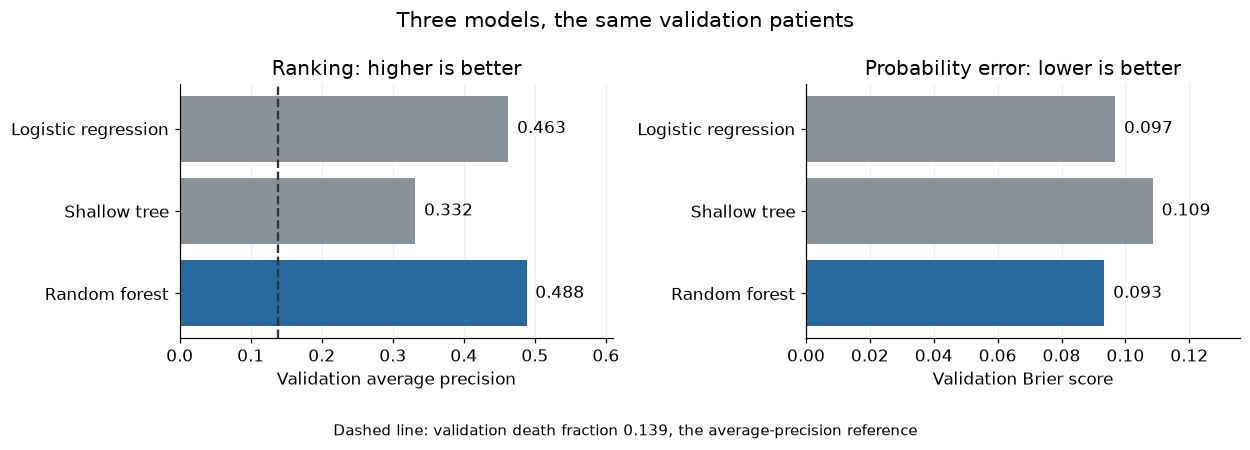

,val_auc,val_pr,val_brier,val_ece
logistic_regression,0.834,0.463,0.097,0.034
decision_tree,0.786,0.332,0.109,0.045
random_forest,0.852,0.488,0.093,0.038


Validation no-skill precision-recall reference: 0.139


The forest's validation average precision is **0.488**, versus **0.463** for logistic regression and **0.332** for the shallow tree. The RF minus LR difference is **+0.026** on these 800 validation stays. Section 6 checks how this comparison changes across development splits.

In [5]:
# Reuse the same development data and tracking settings for each baseline
fit_baseline = partial(
    run_baseline, X_train_t=X_train_t, y_train=y_train,
    X_val_t=X_val_t, y_val=y_val, seed=SEED, start_run=start_run,
)

results = {}

# Logistic regression uses standardised inputs
run, log_reg, _, results["logistic_regression"] = fit_baseline(
    "02-baseline-logistic-regression",
    Pipeline([("scale", StandardScaler()), ("lr", LogisticRegression(max_iter=1000, solver="liblinear", random_state=SEED))]),
    {"model_type": "logistic_regression", "standard_scaling": True, "max_iter": 1000, "solver": "liblinear"}, ["logistic_regression"])
run.finish()

# Decision tree: a shallow reference model
run, dt, _, results["decision_tree"] = fit_baseline(
    "02-baseline-decision-tree", DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=SEED),
    {"model_type": "decision_tree", "max_depth": 4, "min_samples_leaf": 20}, ["decision_tree"])
run.finish()

# Random Forest: oob_score=True keeps the out-of-bag predictions used in sections 7 and 8
run, rf, p_val_rf, results["random_forest"] = fit_baseline(
    "02-baseline-random-forest", RandomForestClassifier(**RF_PARAMS, oob_score=True, random_state=SEED, n_jobs=-1),
    {"model_type": "random_forest", **RF_PARAMS}, ["random_forest"])
imp_df = pd.DataFrame({"feature": feat_names, "impurity_importance": rf.feature_importances_})
log_top_bar(imp_df, "feature", "impurity_importance", "rf_impurity_importance_chart", "RF impurity importance (top 15)")
baseline_df = pd.DataFrame(results).T
log_fig("baseline_comparison", plot_baseline_comparison(baseline_df, float(y_val.mean())), tight=False)
wandb.log({"baseline_comparison_table": wandb.Table(dataframe=baseline_df.rename_axis("model").reset_index())})
run.finish()
display_details_table(baseline_df.round(3), "Detailed baseline metrics")
print(f"Validation no-skill precision-recall reference: {y_val.mean():.3f}")
rf_lr_gap = results["random_forest"]["val_pr"] - results["logistic_regression"]["val_pr"]
display(Markdown(f"The forest's validation average precision is **{results['random_forest']['val_pr']:.3f}**, "
                 f"versus **{results['logistic_regression']['val_pr']:.3f}** for logistic regression "
                 f"and **{results['decision_tree']['val_pr']:.3f}** for the shallow tree. "
                 f"The RF minus LR difference is **{rf_lr_gap:+.3f}** on these 800 validation stays. "
                 "Section 6 checks how this comparison changes across development splits."))


### What the baseline results show

- **The forest leads on ranking and overall probability error:** it has the highest ranking area and average precision, and the lowest Brier score
- **Logistic regression has the smallest binned calibration gap:** 0.034 versus 0.038 for the forest, so the forest does not lead on every measure
- **All three precision-recall scores exceed the random-ranking reference:** the validation death fraction is 0.139, not 0.5
- **The forest leads logistic regression by +0.026 in average precision:** this is one shared split; section 6 examines how the lead changes across repeated fits

A stronger ranking does not by itself establish useful clinical alerts. The calibration gap also depends on how the risk bins are constructed

> Compare ranking, probability error and calibration together before favouring a model

The plotted bars answer the main comparison: the forest has the highest average precision and lowest Brier error. The collapsed detail table retains all four metrics, including logistic regression's smaller calibration gap


# 6. Variation across repeated fits

The forest leads on the first split. Repeated fits test how much that lead depends on the patients or random seed. The baseline forest is refitted five times for each source of randomness, using seeds 43 to 47

- **Model seed:** patients stay fixed while the forest samples and feature choices change
- **Development split:** test patients stay fixed while development patients are reassigned between training and validation

For each new split, also fit LR on the **same patients**. RF minus LR then gives a paired comparison. The standard deviation (SD) describes spread across these five runs. The splits overlap, so these are exploratory repetitions, not independent trials or a significance test

The top-10 SHAP table checks how often each feature appears among the largest average contributions. Each repetition explains 200 validation patients. Both the fitted forest and those patients change, so this table is an exploratory stability check

**W&B evidence:** each fit has its own settings and score. Groups separate seed changes from patient-split changes, while run `03-variance-summary` stores the full results. The left plot shows score spread; the right plot shows the forest-minus-logistic difference on each shared split


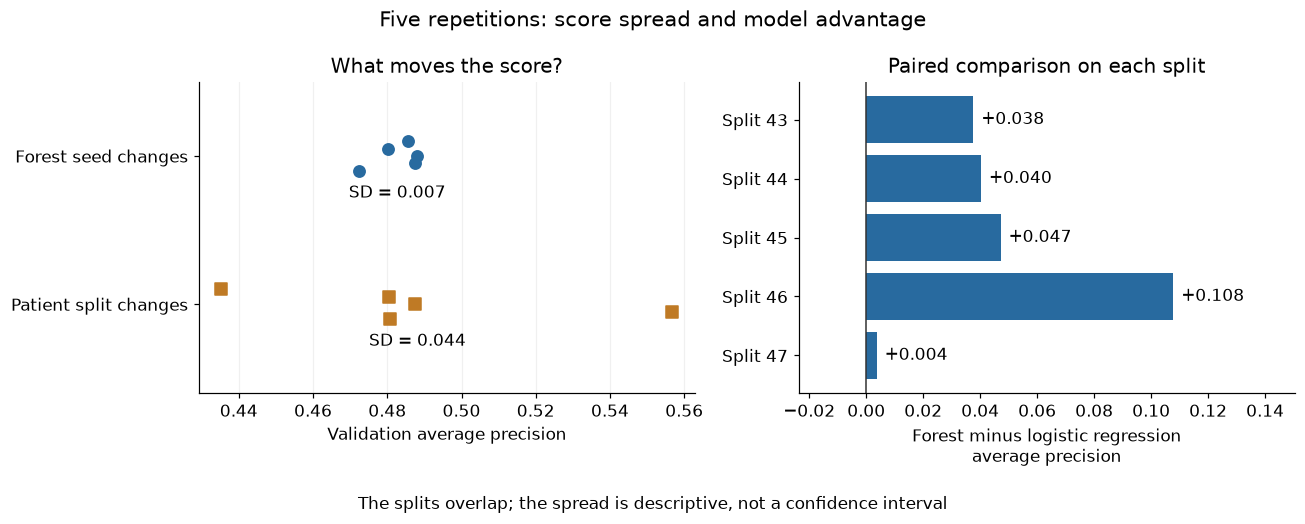

pr                         auc                       brier  \
             mean    std    min    max   mean    std    min    max   mean   
source                                                                      
data_split  0.488  0.044  0.435  0.557  0.838  0.021  0.814  0.860  0.095   
model_seed  0.483  0.007  0.472  0.488  0.851  0.004  0.845  0.855  0.094   

                                 
              std    min    max  
source                           
data_split  0.003  0.091  0.098  
model_seed  0.001  0.093  0.095

,seed,pr,lr_pr,rf_minus_lr_pr
5,43,0.435,0.398,0.038
6,44,0.480,0.440,0.040
7,45,0.487,0.440,0.047
8,46,0.557,0.449,0.108
9,47,0.481,0.477,0.004


RF split-to-split validation AUPRC SD: 0.044 (descriptive only)
RF minus LR: mean +0.047; range +0.004 to +0.108


,feature,times_in_top10,out_of
0,GCS_last,5,5
1,GCS_median,5,5
2,BUN_last,5,5
3,GCS_highest,5,5
4,BUN_first,5,5
5,MechVentDuration,5,5
6,Age,5,5
7,Lactate_last,5,5
8,Temp_median,3,5
9,PaO2_first,2,5


Validation average-precision SD is **0.007** when only the forest seed changes and **0.044** when the development split changes. The RF minus LR difference ranges from **+0.0036** to **+0.1077**. RF leads on all five shared splits, but the size of its lead varies. Five overlapping splits do not establish a general advantage.

In [6]:
N_REPEATS = 5
var_rows, top10_by_split = [], {}

for source in ["model_seed", "data_split"]:
    for rep in range(N_REPEATS):
        s = SEED + rep + 1  # seeds 43 to 47, all different from the main seed 42
        if source == "model_seed":   # same patients, different forest randomness
            Xtr, Xva, ytr, yva, model_seed = X_train_t, X_val_t, y_train, y_val, s
        else:                        # different patients, same forest randomness
            itr, iva, ite = make_split(s, idx_dev=idx_dev, idx_test=idx_test, y=y)
            Xtr, Xva = prepare(X, itr, iva, num_cols=num_cols, cat_cols=cat_cols)
            ytr, yva, model_seed = y.loc[itr], y.loc[iva], SEED

        run = start_run(f"03-variance-{source}-{s}", "variance", config={**RF_PARAMS, "source": source, "split_seed": s if source == "data_split" else SEED,
                                "model_seed": model_seed, "main_split_sha256": SPLIT_SHA256 if source == "model_seed" else None},
                        tags=["variance"], group=f"rf-variance-{source}", inputs=(source == "model_seed"))
        if source == "data_split":
            split_file = OUTPUT_DIR / f"split_manifest_seed{s}.csv"
            split_manifest(itr, iva, ite, ICU=ICU, id_col=ID_COL).to_csv(split_file, index=False)
            run.config.update({"repeat_split_sha256": hashlib.sha256(split_file.read_bytes()).hexdigest()})
            split_artifact = wandb.Artifact(f"icu-development-split-{s}", type="split", metadata={"split_seed": s, "test_seed": SEED})
            split_artifact.add_file(str(split_file))
            run.log_artifact(split_artifact)
            if WANDB_MODE == "online":
                run.use_artifact(DATA_REF)
        model = RandomForestClassifier(**RF_PARAMS, random_state=model_seed, n_jobs=-1).fit(Xtr, ytr)
        sc = score(yva, model.predict_proba(Xva)[:, 1])
        wandb.log({f"val_{k}": v for k, v in sc.items()})
        row = {"source": source, "seed": s, **sc}
        if source == "data_split":
            lr_repeat = clone(log_reg).fit(Xtr, ytr)
            lr_pr = average_precision_score(yva, lr_repeat.predict_proba(Xva)[:, 1])
            row.update(lr_pr=lr_pr, rf_minus_lr_pr=sc["pr"] - lr_pr)
            wandb.log({"lr_val_pr": lr_pr, "rf_minus_lr_val_pr": sc["pr"] - lr_pr})
        var_rows.append(row)
        run.finish()

        if source == "data_split":   # explanation stability: top 10 features by mean |SHAP| on 200 validation patients
            sv_s, _ = rf_shap(model, Xva.sample(n=200, random_state=SEED))
            top10_by_split[s] = pd.Series(np.abs(sv_s).mean(axis=0), index=Xtr.columns).nlargest(10).index.tolist()

var_df = pd.DataFrame(var_rows)
var_summary = var_df.groupby("source")[["pr", "auc", "brier"]].agg(["mean", "std", "min", "max"]).round(3)

SPLIT_SD_PR = float(var_df.loc[var_df.source == "data_split", "pr"].std())
paired = var_df.loc[var_df.source == "data_split", ["seed", "pr", "lr_pr", "rf_minus_lr_pr"]]
print(f"RF split-to-split validation AUPRC SD: {SPLIT_SD_PR:.3f} (descriptive only)")
print(f"RF minus LR: mean {paired.rf_minus_lr_pr.mean():+.3f}; "
      f"range {paired.rf_minus_lr_pr.min():+.3f} to {paired.rf_minus_lr_pr.max():+.3f}")

# How often does each feature reach the top 10 across the 5 split models?
stab = pd.Series([f for top in top10_by_split.values() for f in top]).value_counts().rename_axis("feature").reset_index(name="times_in_top10")
stab["out_of"] = N_REPEATS

run = start_run("03-variance-summary", "variance", config={"n_repeats": N_REPEATS, **RF_PARAMS}, tags=["variance"])
wandb.log({"variance_runs": wandb.Table(dataframe=var_df), "shap_top10_stability": wandb.Table(dataframe=stab),
           "split_sd_val_pr": SPLIT_SD_PR})
log_fig("variance_comparison", plot_variance_comparison(var_df), tight=False)
display_details_table(var_summary, "Detailed score spread")
display_details_table(paired.round(3), "Paired scores on each development split")
display_details_table(stab, "Explanation-ranking stability")
run.finish()
seed_sd = var_df.loc[var_df.source == "model_seed", "pr"].std()
all_positive = bool((paired.rf_minus_lr_pr > 0).all())
display(Markdown(f"Validation average-precision SD is **{seed_sd:.3f}** when only the forest seed changes "
                 f"and **{SPLIT_SD_PR:.3f}** when the development split changes. "
                 f"The RF minus LR difference ranges from **{paired.rf_minus_lr_pr.min():+.4f}** "
                 f"to **{paired.rf_minus_lr_pr.max():+.4f}**. "
                 + ("RF leads on all five shared splits, but the size of its lead varies. " if all_positive
                    else "The lead changes or reaches zero across these shared splits. ")
                 + "Five overlapping splits do not establish a general advantage."))


### What the repeated fits show

- **Forest randomness moves the score relatively little:** average-precision SD is 0.007 when only the model seed changes
- **The patient split matters more:** SD rises to 0.044 when the development split changes; forest average precision ranges from 0.435 to 0.557
- **The forest leads on all five shared splits:** its advantage over logistic regression ranges from +0.004 to +0.108, with a mean of +0.047
- **Eight inputs appear in all five top-10 SHAP lists:** these include responsiveness summaries and blood urea nitrogen measurements

The lead is consistent in direction here, but its size depends on the patients used for fitting and validation. Five overlapping splits do not prove an advantage in a new population. Stable explanation rankings do not establish causes of death

> Check a model's advantage across shared development splits before treating one good score as dependable

Method: [held-out evaluation and model selection](https://scikit-learn.org/stable/modules/cross_validation.html)


# 7. Inside the forest: how trees become one risk

Each tree asks a sequence of questions and reaches a leaf. Its probability is the fraction of death labels in that leaf's **bootstrap training sample**, where sampled stays can appear more than once. The forest averages those probabilities. These are probability votes, not just yes/no votes

The following plots trace one patient, compare individual trees with the forest, and show how validation performance changes as tree probabilities are averaged

**Out-of-bag (OOB) prediction:** average only trees whose bootstrap samples excluded that training stay. This provides an internal check without fitting another forest. The imputer was fitted on all training inputs, so this is not a fully held-out evaluation of preprocessing. The validation set remains separate

Method: [scikit-learn RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)

**W&B evidence:** run `04-inside-the-forest` stores the vote histogram, `decision_path_tree0`, the tree-count curve and patient disagreement table. The path table makes one prediction inspectable; the run links that explanation to the forest settings used to produce it


## 7.1 One patient, 300 tree probabilities

The histogram shows validation stay 135576, a patient who died. This example has the greatest tree spread among the validation deaths and was selected to make disagreement visible

Individual trees give very different probabilities, but their average is about **55%**, marked by the red line. Tree 0 gives **30%**. Its path ends at a leaf with **eight distinct training stays and bootstrap weight ten**

The leaf's weighted death fraction is 0.300, exactly matching tree 0's vote. Across all 800 validation patients, the largest difference between the forest prediction and the mean of tree probabilities is **1.1e-16**, a floating-point rounding difference


Forest risk = mean of tree votes? Largest difference over 800 patients: 1.1e-16


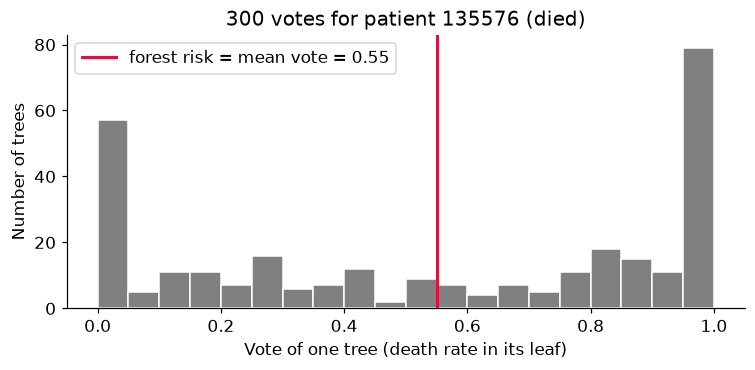

,depth,question_answered,patient_value,distinct_training_stays_in_node,bootstrap_weight_in_node,death_rate_in_node
0,0,SOFA > 13.50,17.0,1543,2400.0,0.141
1,1,GCS_last <= 8.50,8.0,72,120.0,0.508
2,2,Creatinine_first > 1.70,6.5,43,73.0,0.658
3,3,DiasABP_highest > 80.50,94.0,26,49.0,0.796
4,4,LEAF: this is the tree's vote,NaN,8,10.0,0.300


Leaf death rate = tree 0 vote: 0.300 vs 0.300


In [7]:
run = start_run("04-inside-the-forest", "transparency", config={**RF_PARAMS}, tags=["transparency", "random_forest"])

# Vote of every tree for every validation patient: shape (n_trees, n_patients)
X_val_np = X_val_t.to_numpy()
tree_probs = np.stack([t.predict_proba(X_val_np)[:, 1] for t in rf.estimators_])
max_gap = float(np.abs(tree_probs.mean(axis=0) - p_val_rf).max())
print(f"Forest risk = mean of tree votes? Largest difference over {tree_probs.shape[1]} patients: {max_gap:.1e}")

# --- 7.1 One patient: the validation patient who died and on whom the trees disagree most ---
tree_sd = tree_probs.std(axis=0)
np.testing.assert_allclose(tree_probs.mean(axis=0), p_val_rf, atol=1e-12, rtol=0)
deaths = np.where(y_val.values == 1)[0]
focus = int(deaths[np.argmax(tree_sd[deaths])])
focus_id = int(ICU.loc[idx_val[focus], ID_COL])

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(tree_probs[:, focus], bins=np.linspace(0, 1, 21), color="grey", edgecolor="white")
ax.axvline(p_val_rf[focus], color="crimson", lw=2, label=f"forest risk = mean vote = {p_val_rf[focus]:.2f}")
ax.set_xlabel("Vote of one tree (death rate in its leaf)"); ax.set_ylabel("Number of trees")
ax.set_title(f"300 votes for patient {focus_id} (died)"); ax.legend()
log_fig("votes_focus_patient", fig)

# Full path of this patient through tree number 0
tree0, t = rf.estimators_[0], rf.estimators_[0].tree_
x = X_val_np[[focus]]
rows = []
for depth, node in enumerate(tree0.decision_path(x).indices):
    rate = float(t.value[node, 0, 1] / t.value[node, 0].sum())
    if t.children_left[node] == -1:
        rule, value = "LEAF: this is the tree's vote", np.nan
    else:
        f, thr = t.feature[node], t.threshold[node]
        value = float(x[0, f])
        rule = f"{feat_names[f]} {'<=' if value <= thr else '>'} {thr:.2f}"
    rows.append({"depth": depth, "question_answered": rule, "patient_value": value,
                 "distinct_training_stays_in_node": int(t.n_node_samples[node]),
                 "bootstrap_weight_in_node": float(t.weighted_n_node_samples[node]), "death_rate_in_node": round(rate, 3)})
path_df = pd.DataFrame(rows)
display(path_df)
print(f"Leaf death rate = tree 0 vote: {rows[-1]['death_rate_in_node']:.3f} vs {tree_probs[0, focus]:.3f}")
wandb.log({"decision_path_tree0": wandb.Table(dataframe=path_df.astype({"patient_value": float}))})

## 7.2 Individual trees versus the forest

Tree depth counts the longest sequence of questions; leaves are the endpoints. The histograms describe their variation across this forest

The mean validation ranking area across individual trees is **0.650**, compared with **0.852** for the forest. The value 0.650 summarises all individual-tree scores; it is not tree 0's score

Averaging many imperfect trees improves ranking on these validation patients. The result depends on the fitted trees and data; model size alone does not guarantee better prediction


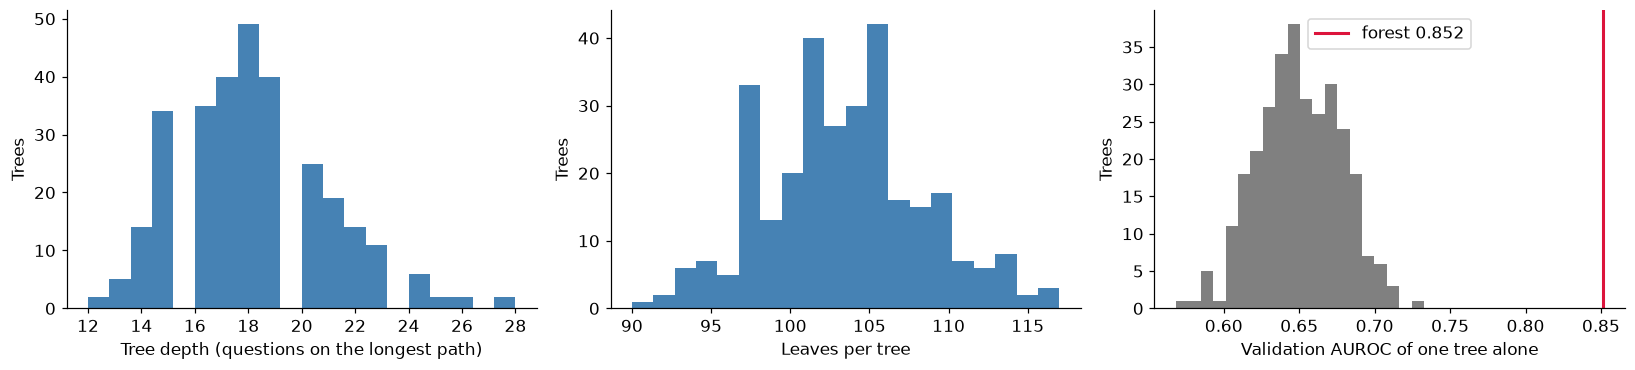

Mean single-tree AUROC 0.650 vs forest AUROC 0.852


In [8]:
anat = pd.DataFrame({
    "tree": range(len(rf.estimators_)),
    "depth": [e.get_depth() for e in rf.estimators_],
    "leaves": [e.get_n_leaves() for e in rf.estimators_],
    "val_auc_single_tree": [roc_auc_score(y_val, tp) for tp in tree_probs],
})
forest_auc = results["random_forest"]["val_auc"]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].hist(anat["depth"], bins=20, color="steelblue"); axes[0].set_xlabel("Tree depth (questions on the longest path)")
axes[1].hist(anat["leaves"], bins=20, color="steelblue"); axes[1].set_xlabel("Leaves per tree")
axes[2].hist(anat["val_auc_single_tree"], bins=20, color="grey")
axes[2].axvline(forest_auc, color="crimson", lw=2, label=f"forest {forest_auc:.3f}"); axes[2].legend()
axes[2].set_xlabel("Validation AUROC of one tree alone")
for a in axes: a.set_ylabel("Trees")
log_fig("forest_anatomy", fig)
wandb.log({"forest_anatomy_table": wandb.Table(dataframe=anat), "mean_tree_depth": anat["depth"].mean(),
           "mean_leaves": anat["leaves"].mean(), "mean_single_tree_auc": anat["val_auc_single_tree"].mean()})
print(f"Mean single-tree AUROC {anat['val_auc_single_tree'].mean():.3f} vs forest AUROC {forest_auc:.3f}")

## 7.3 Adding trees and checking internal predictions

The curve averages the first 1, 2, ..., 300 trees from the already fitted forest. No new models are selected using this curve

| Trees averaged | Validation average precision |
|---|---|
| 1 | 0.276 |
| 10 | 0.451 |
| 50 | 0.485 |
| 300 | 0.488 |

Most of the gain occurs within the first 50 trees. The remaining trees change average precision from 0.485 to 0.488, so the curve is close to a plateau

OOB average precision is **0.481**, close to the separate validation score of **0.488**. These checks concern different patients and prediction procedures; close numbers do not make them interchangeable


AUPRC with 1, 10, 50, 300 trees: 0.276, 0.451, 0.485, 0.488
OOB AUPRC on training patients 0.481 vs validation AUPRC 0.488


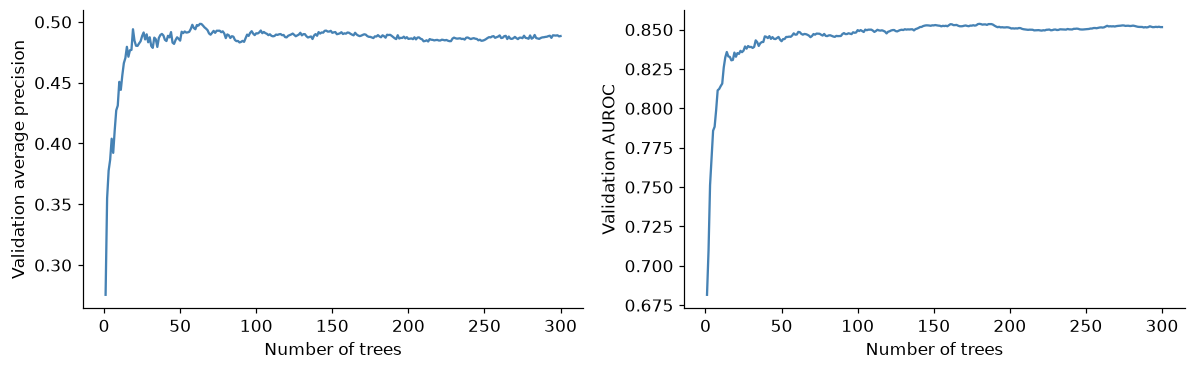

In [9]:
k = np.arange(1, len(rf.estimators_) + 1)
cum = np.cumsum(tree_probs, axis=0) / k[:, None]           # forest of the first k trees
pr_by_k = [average_precision_score(y_val, c) for c in cum]
auc_by_k = [roc_auc_score(y_val, c) for c in cum]
wandb.log({"performance_vs_n_trees": wandb.plot.line_series(
    xs=k.tolist(), ys=[pr_by_k, auc_by_k], keys=["val AUPRC", "val AUROC"],
    title="Validation performance of a forest made of the first k trees", xname="number of trees")})

oob_p = rf.oob_decision_function_[:, 1]
ok = np.isfinite(oob_p) & (rf.oob_decision_function_.sum(axis=1) > 0)
oob_pr = average_precision_score(y_train.iloc[np.flatnonzero(ok)], oob_p[ok])
wandb.log({"oob_pr": oob_pr})
print(f"AUPRC with 1, 10, 50, 300 trees: {pr_by_k[0]:.3f}, {pr_by_k[9]:.3f}, {pr_by_k[49]:.3f}, {pr_by_k[-1]:.3f}")
print(f"OOB AUPRC on training patients {oob_pr:.3f} vs validation AUPRC {results['random_forest']['val_pr']:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(k, pr_by_k, color="steelblue")
axes[1].plot(k, auc_by_k, color="steelblue")
for ax, label in zip(axes, ["Validation average precision", "Validation AUROC"]):
    ax.set(xlabel="Number of trees", ylabel=label)
log_fig("performance_vs_trees_notebook", fig)

## 7.4 Tree disagreement and predicted risk

Each point represents one validation patient. The horizontal axis is average forest risk; the vertical axis is the SD across its 300 tree probabilities

The dashed boundary is the largest possible SD for probabilities between 0 and 1 at that mean: √[p(1−p)]. It is highest near 0.5 and falls towards zero near either end

The earlier example, with average risk near 0.55, combines many low and high tree probabilities. Its spread reveals disagreement inside this fitted forest, not a confidence interval for the patient's true risk


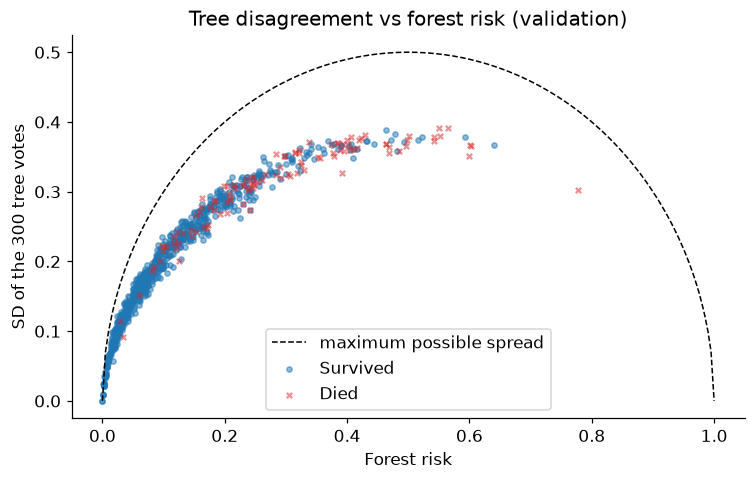

In [10]:
# Show raw tree spread. This is a description of the ensemble, not an uncertainty interval
fig, ax = plt.subplots(figsize=(7, 4.5))
grid = np.linspace(0, 1, 200)
ax.plot(grid, np.sqrt(grid * (1 - grid)), "k--", lw=1, label="maximum possible spread")
for lab, col, name in [(0, "tab:blue", "Survived"), (1, "tab:red", "Died")]:
    m = y_val.values == lab
    ax.scatter(p_val_rf[m], tree_sd[m], s=12, alpha=0.5, color=col,
               marker="o" if lab == 0 else "x", label=name)
ax.set_xlabel("Forest risk"); ax.set_ylabel("SD of the 300 tree votes"); ax.legend()
ax.set_title("Tree disagreement vs forest risk (validation)")
log_fig("tree_disagreement", fig)
disagree_df = pd.DataFrame({"recordid": ICU.loc[idx_val, ID_COL].values, "y_true": y_val.values,
                            "forest_risk": p_val_rf, "tree_sd": tree_sd})
wandb.log({"tree_disagreement_val": wandb.Table(dataframe=disagree_df)})
run.finish()

### What the forest plots show

- **The averaging rule is verified:** mean tree probability reproduces the forest prediction to numerical precision
- **One path explains one vote:** the displayed leaf gives 30%, while all trees average to about 55% for the same patient
- **The ensemble ranks better than its average individual tree:** 0.852 versus 0.650 on validation
- **Extra trees have diminishing returns here:** average precision is 0.485 at 50 trees and 0.488 at 300
- **Disagreement remains descriptive:** it shows where trees differ, without giving a validated uncertainty interval

> Follow tree probabilities and their average to understand how a forest calculates risk


# 8. Explain the model and check the explanation

These analyses describe the fitted baseline forest from section 5

| Method | What it explains | What the check establishes |
|---|---|---|
| SHAP | Contributions of recorded inputs to a prediction | Contributions plus a reference recover the prediction |
| Response curves | The model response when one input changes | Individual responses can differ from the average |
| Optional surrogate | A smaller tree's approximation to the forest | Agreement must be measured; this extension was skipped |
| Shuffled outcomes | Feature rankings after the original input-outcome pairing is broken | A complete ranking can accompany weak prediction |

These tools explain model behaviour. They do not establish treatments or causes, and they do not automatically describe the final model refitted in section 10


## 8.1 SHAP: contributions to a prediction

SHAP assigns a contribution to each input. Positive values raise the prediction from a reference value; negative values lower it. A contribution of +0.05 adds 5 percentage points to the predicted probability

Here the reference is **0.139**, derived from stored training paths in the tree-path-dependent method. It is not defined as the observed death rate, even though the rounded values are close in this run

The sum check compares reference plus contributions with the forest prediction for 500 validation patients. Its largest gap is **3.3e-14**, so the arithmetic agrees to numerical precision

In the summary plot, dot colour shows the input value and horizontal position shows its contribution. In a waterfall plot, red contributions raise the prediction and blue contributions lower it

The Glasgow Coma Scale (GCS) measures responsiveness. Blood urea nitrogen (BUN) is a kidney-related blood test. `last`, `highest` and `median` identify summaries within the first 48 h

Method: [SHAP TreeExplainer](https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html)

**W&B evidence:** run `05-explanations` stores the global plots, two patient waterfalls and `patient_explanations_val`. That table connects a stay identifier, prediction, observed outcome and top contributions. The browser can filter the table; generating a new waterfall still requires the notebook calculation


SHAP reference value (tree-path background): 0.139
Additivity check, largest gap over 500 patients: 3.3e-14


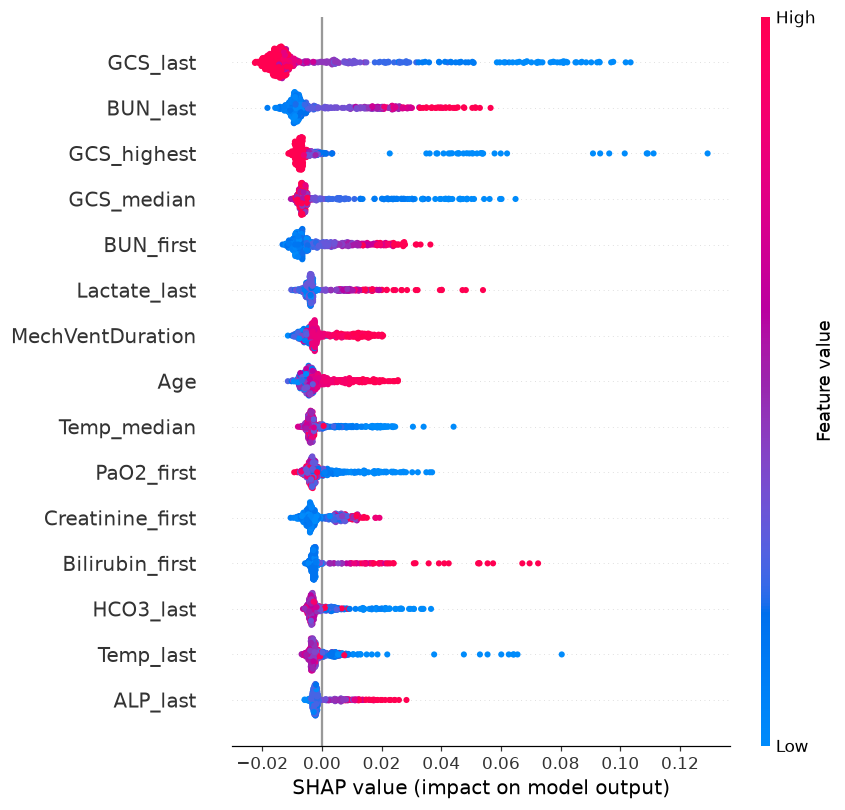

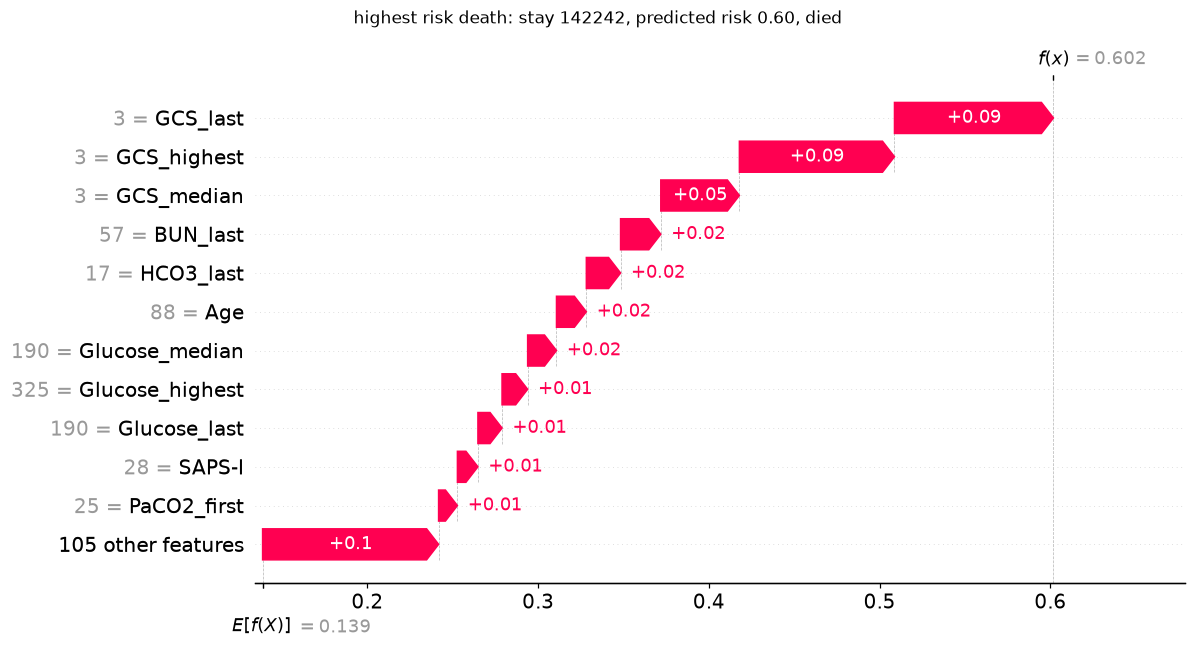

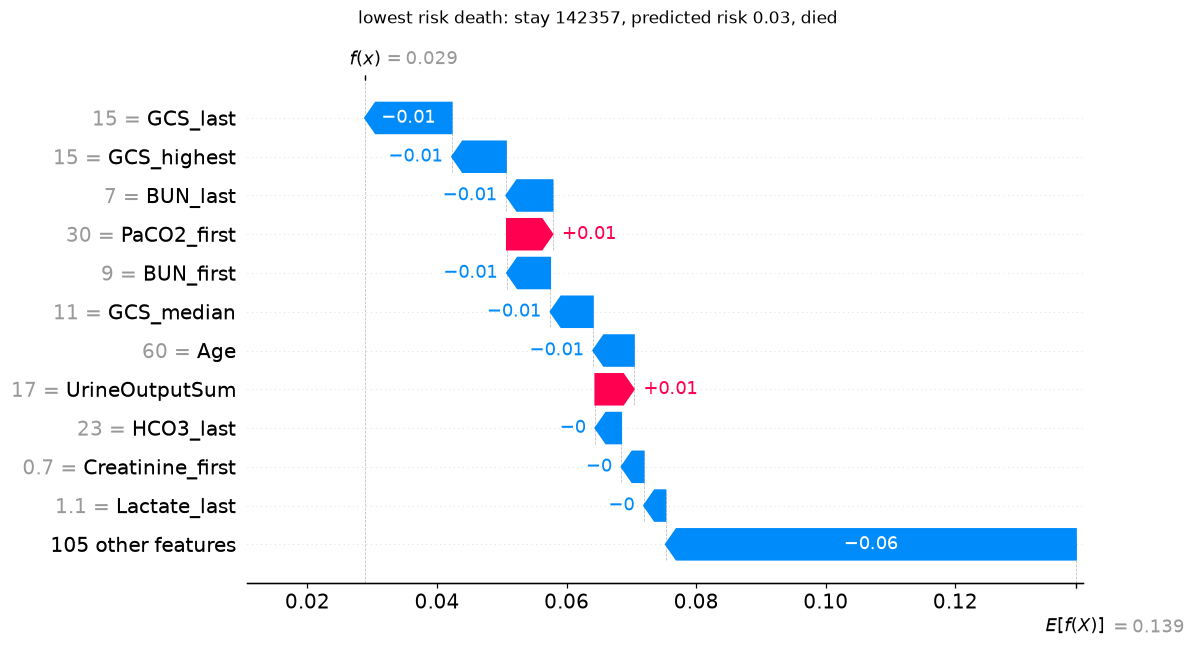

Top 3 features by mean |SHAP|: ['GCS_last', 'BUN_last', 'GCS_highest']


The largest average absolute contributions in these **500** validation stays are `GCS_last`, `BUN_last`, `GCS_highest`. The largest contribution-sum gap is **3.3e-14**; the arithmetic check passes. This verifies the decomposition of predictions, not a biological explanation.

In [11]:
run = start_run("05-explanations", "interpretability", config={"shap_sample_size": 500, "shap_method": "tree_path_dependent", **RF_PARAMS},
                tags=["interpretability", "random_forest"])

shap_X = X_val_t.sample(n=min(500, len(X_val_t)), random_state=SEED)
sv, base_value = rf_shap(rf, shap_X)
p_shap = rf.predict_proba(shap_X)[:, 1]

# Additivity check: SHAP reference + sum of the 116 SHAP values = this patient's predicted risk
add_gap = float(np.abs(base_value + sv.sum(axis=1) - p_shap).max())
print(f"SHAP reference value (tree-path background): {base_value:.3f}")
print(f"Additivity check, largest gap over {len(p_shap)} patients: {add_gap:.1e}")
np.testing.assert_allclose(base_value + sv.sum(axis=1), p_shap, atol=1e-7, rtol=0)
wandb.log({"shap_base_value": base_value, "shap_additivity_max_gap": add_gap})

# Global view
shap.summary_plot(sv, shap_X, show=False, max_display=15, rng=np.random.default_rng(SEED))
log_fig("shap_summary_plot", plt.gcf())
shap_df = pd.DataFrame({"feature": feat_names, "mean_abs_shap": np.abs(sv).mean(axis=0)}).sort_values("mean_abs_shap", ascending=False)
log_top_bar(shap_df, "feature", "mean_abs_shap", "rf_shap_importance_chart", "RF mean |SHAP| (top 15)")

# Local view: per-patient table with the 3 strongest drivers and tree disagreement from section 7
pos = idx_val.get_indexer(shap_X.index)
top3 = np.argsort(-np.abs(sv), axis=1)[:, :3]
y_s = y_val.loc[shap_X.index].values
expl_df = pd.DataFrame({
    "recordid": ICU.loc[shap_X.index, ID_COL].values, "y_true": y_s, "forest_risk": p_shap,
    "tree_sd": tree_sd[pos],
    "top_3_drivers": [", ".join(f"{feat_names[j]} ({sv[r, j]:+.3f})" for j in top3[r]) for r in range(len(sv))],
})
wandb.log({"patient_explanations_val": wandb.Table(dataframe=expl_df)})

# Waterfalls: the death ranked highest and the death ranked lowest by the forest
d_idx = np.where(y_s == 1)[0]
for label, i in {"highest_risk_death": d_idx[np.argmax(p_shap[d_idx])], "lowest_risk_death": d_idx[np.argmin(p_shap[d_idx])]}.items():
    shap.plots.waterfall(shap.Explanation(values=sv[i], base_values=base_value, data=shap_X.iloc[i].values,
                                          feature_names=feat_names), max_display=12, show=False)
    fig = plt.gcf(); fig.set_size_inches(11, 6)
    fig.suptitle(f"{label.replace(chr(95), chr(32))}: stay {expl_df.recordid.iloc[i]}, predicted risk {p_shap[i]:.2f}, died", fontsize=11)
    fig.tight_layout()
    log_fig(f"shap_waterfall_{label}", fig)

TOP_SHAP = shap_df["feature"].head(3).tolist()
print("Top 3 features by mean |SHAP|:", TOP_SHAP)
display(Markdown(f"The largest average absolute contributions in these **{len(shap_X)}** validation stays are "
                 + ", ".join(f"`{f}`" for f in TOP_SHAP)
                 + f". The largest contribution-sum gap is **{add_gap:.1e}**; the arithmetic check passes. "
                 + "This verifies the decomposition of predictions, not a biological explanation."))
run.finish()

### What the SHAP results show

- **Overall contributions:** `GCS_last`, `BUN_last` and `GCS_highest` have the largest average absolute contributions. This describes influence, not whether an input always raises risk
- **Highest-risk death, stay 142242:** predicted risk is **60.2%**. Low recorded responsiveness scores push it upwards; the last and highest GCS contributions each add about 9 percentage points
- **Lowest-risk death, stay 142357:** predicted risk is only **2.9%**, despite the observed death. The last GCS, highest GCS and last BUN contributions lower it by about 1.3, 0.8 and 0.7 percentage points respectively
- **The explanation sum passes:** reference plus all contributions matches the prediction, with a maximum gap of 3.3e-14

These patients were selected as extremes among the explained deaths. They are not typical cases or threshold-defined errors. The lowest-risk death shows why a model can give a plausible explanation for a prediction that does not anticipate the outcome

Related inputs share information, so their allocated contributions depend on the explanation method. The arithmetic check validates the decomposition, not a biological explanation

> Check contribution sums and individual cases before treating an explanation as trustworthy


## 8.2 Response curves: one input, many patients

A partial dependence plot (PDP) averages predictions while one input changes and the other recorded inputs stay fixed. Individual conditional expectation (ICE) curves show responses for separate patients

The plotted input is `GCS_last`, the last responsiveness score. Grey curves show 100 sampled validation patients; the red curve averages predictions across the validation data

This separates the model's average response from the variation between individual patients

**W&B evidence:** run `05b-response-curves` records the chosen input and the saved plot. The changing input is explicit, so this model-response example can be traced back to its configuration


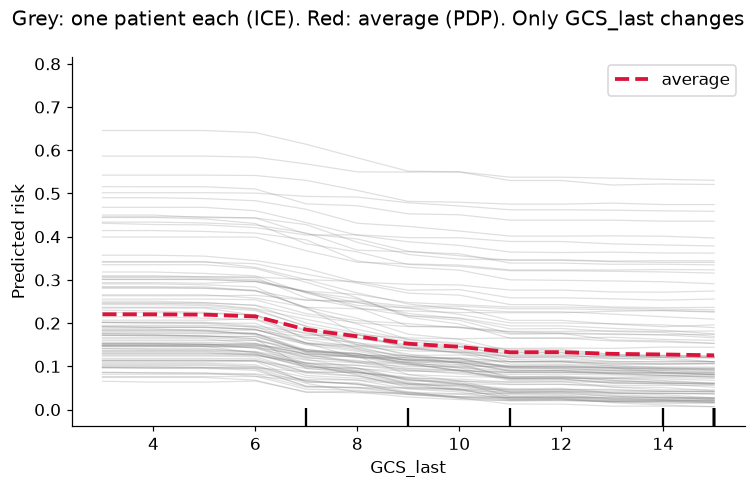

In [12]:
run = start_run("05b-response-curves", "interpretability", config={"pdp_feature": TOP_SHAP[0], "ice_patients": 100},
                tags=["interpretability"])
fig, ax = plt.subplots(figsize=(7, 4.5))
PartialDependenceDisplay.from_estimator(
    rf, X_val_t, features=[TOP_SHAP[0]], kind="both", subsample=100, random_state=SEED, grid_resolution=30, ax=ax,
    ice_lines_kw={"color": "grey", "alpha": 0.25, "lw": 0.8}, pd_line_kw={"color": "crimson", "lw": 2.5})
plt.gcf().axes[-1].set_ylabel("Predicted risk")
plt.gcf().suptitle(f"Grey: one patient each (ICE). Red: average (PDP). Only {TOP_SHAP[0]} changes")
log_fig("pdp_ice_top_feature", plt.gcf())
run.finish()

### What the response curves show

- **Average predicted risk falls as the last responsiveness score rises:** this is the downward red curve
- **Patients start at different risk levels and show different-sized reductions:** the grey curves reveal variation hidden by one average
- **The short marks on the horizontal axis show observed input values:** they locate the data supporting the displayed range

Only the last score varies; the highest and median scores stay as recorded. Some generated combinations are therefore unrealistic. The plot describes the model response, not a treatment effect or a rule for changing care

> Read individual response curves alongside the average and question whether the generated combinations are realistic

Method: [partial dependence and individual response curves](https://scikit-learn.org/stable/modules/partial_dependence.html)


## 8.3 Optional surrogate: a smaller approximation to the forest

A **surrogate** is a simpler model trained to imitate another model's predictions. This optional code uses the baseline forest's probabilities on training patients as its target, rather than the observed death labels

When enabled, it fits trees with depths 1 to 5. **Fidelity R²** measures their agreement with the forest on validation patients: 1 is perfect agreement, 0 matches a constant validation-mean reference, and negative values are worse

This extension was disabled in the saved run. No fitted surrogate or measured fidelity is reported below; the completed SHAP and response-curve analyses remain separate


In [13]:
if RUN_SURROGATE:
    run = start_run("06-global-surrogate", "interpretability", config={"surrogate_min_samples_leaf": 30},
                    tags=["interpretability", "surrogate"])
    forest_training_risk = rf.predict_proba(X_train_t)[:, 1]
    rows = []
    for depth in range(1, 6):
        sur = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=30, random_state=SEED).fit(X_train_t, forest_training_risk)
        s_val = sur.predict(X_val_t)
        rows.append({"depth": depth, "leaves": sur.get_n_leaves(), "fidelity_r2_val": r2_score(p_val_rf, s_val),
                     "mean_abs_risk_gap_val": np.mean(np.abs(p_val_rf - s_val))})
    sur_df = pd.DataFrame(rows)
    display(sur_df.round(3))
    wandb.log({"surrogate_fidelity": wandb.plot.line_series(
        xs=sur_df["depth"].tolist(), ys=[sur_df["fidelity_r2_val"].tolist()],
        keys=["fidelity R²"], title="Surrogate fidelity vs depth", xname="max depth"),
        "surrogate_table": wandb.Table(dataframe=sur_df)})
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(sur_df.depth, sur_df.fidelity_r2_val, marker="o", color="steelblue")
    axes[1].plot(sur_df.depth, sur_df.mean_abs_risk_gap_val * 100, marker="o", color="steelblue")
    axes[0].set(xlabel="Maximum depth", ylabel="Fidelity R²", title="Agreement with the forest")
    axes[1].set(xlabel="Maximum depth", ylabel="Mean absolute gap (percentage points)", title="Probability gap from the forest")
    log_fig("surrogate_fidelity_notebook", fig)

    SURROGATE_DEPTH = 3
    sur3 = DecisionTreeRegressor(max_depth=SURROGATE_DEPTH, min_samples_leaf=30, random_state=SEED).fit(X_train_t, forest_training_risk)
    SURROGATE_R2 = float(sur_df.loc[sur_df.depth == SURROGATE_DEPTH, "fidelity_r2_val"].iloc[0])
    fig, ax = plt.subplots(figsize=(15, 6))
    plot_tree(sur3, feature_names=feat_names, filled=True, rounded=True, fontsize=9, precision=2, ax=ax)
    ax.set_title(f"Depth-{SURROGATE_DEPTH} surrogate of the forest, fidelity R² = {SURROGATE_R2:.2f} (leaf value = mean forest risk)")
    log_fig("surrogate_tree_depth3", fig)
    run.finish()
else:
    print("Optional surrogate skipped")

Optional surrogate skipped


### How to interpret the optional surrogate

The saved output confirms **"Optional surrogate skipped"**. No numerical agreement claim can be made for this run

A depth-3 surrogate allows up to three questions on a patient path and up to seven split nodes across the tree. Its leaf values would represent average forest predictions, not observed death rates

Even strong agreement would mean that the small tree imitates this baseline forest. It would not establish clinical accuracy or explain the final refitted model

> Report agreement with the forest before using a small tree as its explanation


## 8.4 Sanity check: a ranking is not evidence of useful prediction

Training outcomes are shuffled before another forest is fitted with the same settings. This breaks the original input-outcome pairing. Validation outcomes remain unchanged

The shuffled model still produces **impurity importance**, its built-in relative feature ranking. These values normally sum to one even when prediction is poor, so a nonzero ranking alone cannot establish useful information

The permutation check shuffles each of this model's ten highest-ranked inputs in the validation data. The drop in average precision measures that input's contribution to performance for this fitted model. Related inputs can make individual contributions harder to detect

One shuffled run is an illustration, not a formal test, and its scores need not equal chance exactly

Method: [permutation importance and its limits](https://scikit-learn.org/stable/modules/permutation_importance.html)

**W&B evidence:** run `07-explanation-sanity-check` records the shuffled-label settings, performance and feature checks. The first plot below shows the performance collapse; the following ranking demonstrates why an attractive explanation alone is not enough


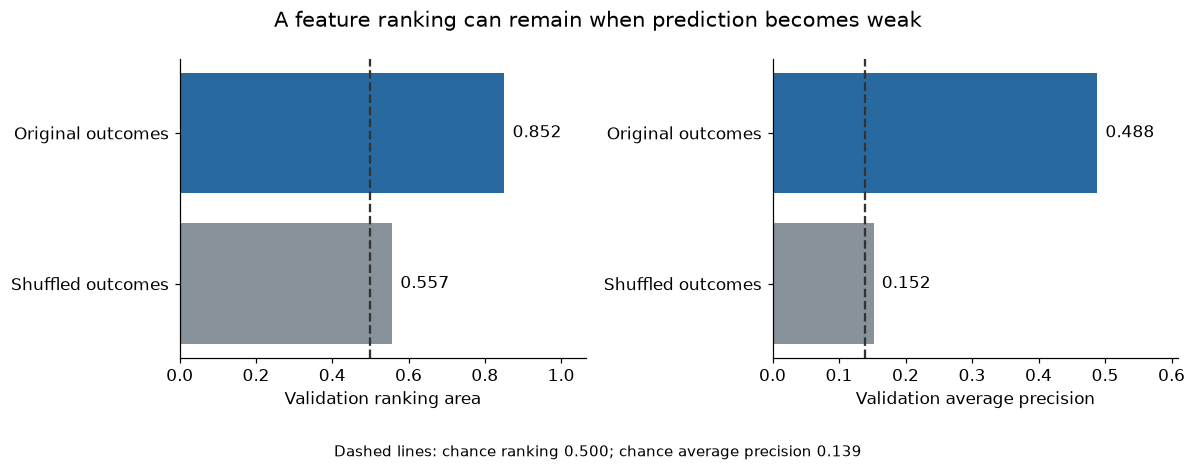

,AUROC,average precision
real labels,0.852,0.488
shuffled training labels,0.557,0.152
chance reference,0.500,0.139


,feature,impurity_real,impurity_shuffled,permutation_drop_real,permutation_drop_shuffled
2,Age,0.0153,0.0194,0.0100,-0.0038
22,Glucose_last,0.0127,0.0167,0.0012,0.0012
98,HCT_last,0.0083,0.0162,0.0031,0.0007
85,WBC_first,0.0101,0.0161,-0.0001,0.0010
81,Platelets_first,0.0113,0.0158,0.0015,0.0007
74,HCT_first,0.0074,0.0156,-0.0009,0.0001
5,Weight,0.0120,0.0154,0.0007,0.0022
23,HR_last,0.0107,0.0152,0.0057,0.0023
109,WBC_last,0.0179,0.0140,0.0034,-0.0003
68,BUN_first,0.0204,0.0138,-0.0010,-0.0036


Sum of shuffled-model impurity importances: 1.000


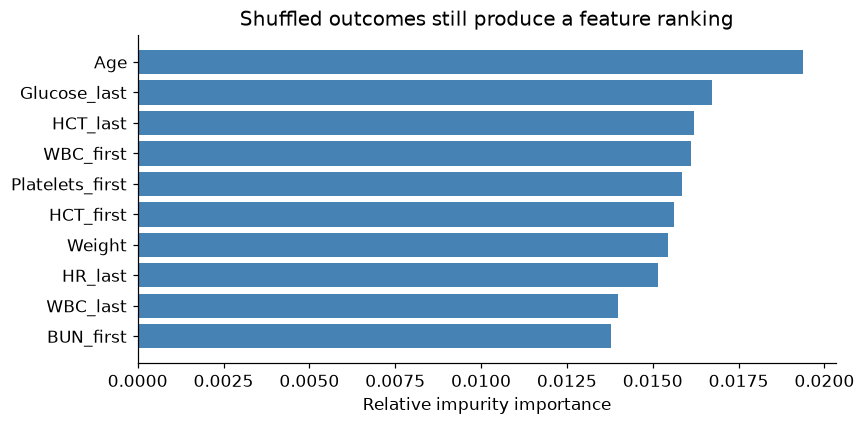

The shuffled-outcome forest has validation AUROC **0.557** and average precision **0.152**, compared with chance references of **0.500** and **0.139**. Its importances still sum to **1.000**. On validation, shuffling one of its top 10 features changes average precision by at most **0.004**. A complete-looking ranking can accompany poor prediction.

In [14]:
run = start_run("07-explanation-sanity-check", "sanity-check", config={**RF_PARAMS, "label_shuffle_seed": SEED},
                tags=["interpretability", "sanity-check"])
rng = np.random.default_rng(SEED)
y_shuffled = pd.Series(rng.permutation(y_train.values), index=y_train.index)
rf_null = RandomForestClassifier(**RF_PARAMS, random_state=SEED, n_jobs=-1).fit(X_train_t, y_shuffled)
null_scores = score(y_val, rf_null.predict_proba(X_val_t)[:, 1])
null_comparison = pd.DataFrame({
    "real labels": {"AUROC": forest_auc, "average precision": results["random_forest"]["val_pr"]},
    "shuffled training labels": {"AUROC": null_scores["auc"], "average precision": null_scores["pr"]},
    "chance reference": {"AUROC": 0.5, "average precision": y_val.mean()},
}).T
log_fig("sanity_performance_comparison", plot_sanity_comparison(null_comparison), tight=False)
display_details_table(null_comparison.round(3), "Real versus shuffled model metrics")
check_df = pd.DataFrame({"feature": feat_names, "impurity_real": rf.feature_importances_,
                         "impurity_shuffled": rf_null.feature_importances_})
# Validation permutation check on the shuffled model's top 10 impurity features (5 shuffles each)

top10 = check_df.nlargest(10, "impurity_shuffled").copy()
top10["permutation_drop_real"] = [perm_drop(rf, f, X_val_t, y_val, seed=SEED) for f in top10.feature]
top10["permutation_drop_shuffled"] = [perm_drop(rf_null, f, X_val_t, y_val, seed=SEED) for f in top10.feature]
display_details_table(top10.round(4), "Feature permutation checks")
print(f"Sum of shuffled-model impurity importances: {rf_null.feature_importances_.sum():.3f}")
fig, ax = plt.subplots(figsize=(8, 4))
top = check_df.nlargest(10, "impurity_shuffled").sort_values("impurity_shuffled")
ax.barh(top.feature, top.impurity_shuffled, color="steelblue")
ax.set(xlabel="Relative impurity importance", title="Shuffled outcomes still produce a feature ranking")
log_fig("sanity_check_importance", fig)
wandb.log({"sanity_check_table": wandb.Table(dataframe=check_df), "sanity_check_top10": wandb.Table(dataframe=top10),
           "null_val_auc": null_scores["auc"], "null_val_pr": null_scores["pr"]})
display(Markdown(f"The shuffled-outcome forest has validation AUROC **{null_scores['auc']:.3f}** "
                 f"and average precision **{null_scores['pr']:.3f}**, compared with chance references "
                 f"of **0.500** and **{y_val.mean():.3f}**. Its importances still sum to **1.000**. "
                 f"On validation, shuffling one of its top 10 features changes average precision by at most "
                 f"**{top10.permutation_drop_shuffled.abs().max():.3f}**. A complete-looking ranking can accompany poor prediction."))
run.finish()

### What the shuffled-outcome results show

- **Prediction deteriorates while the ranking remains:** the shuffled scores are much closer to chance, yet the importances still sum to 1.000
- **Its top inputs contribute little on validation:** shuffling one changes average precision by at most about 0.004 in absolute value
- **The real model shows a larger drop for age:** average precision falls by about 0.010, compared with a small negative change for the shuffled model

Small positive or negative changes can reflect noise. A tidy ordering does not establish predictive value, and overlap between rankings does not prove a specific source of bias

> Check held-out prediction before trusting a feature ranking


# 9. Tune the forest and track the trade-offs

A W&B **sweep** tries settings and records validation scores. The Bayesian search uses earlier results to guide later trials. Selection uses completed runs with a finite validation average precision

Four settings vary: number of trees, maximum depth, features considered at a split and minimum leaf size. Class weights stay at their defaults. In the configuration, depth 0 means no depth limit

- `train_pr` and `val_pr` measure training and validation average precision
- `overfit_gap_pr` is their difference; a large gap shows poor transfer of training performance to validation
- `mean_tree_depth` and `mean_leaves` describe tree size
- `fit_seconds` records training time on this computer
- `oob_pr` and `val_ece` add internal-prediction and calibration checks

Parallel Coordinates connects settings and results for each run. Parameter Importance describes settings associated with the validation score; SHAP instead describes patient inputs contributing to predictions

**W&B evidence:** `wandb.sweep` defines the search and `wandb.agent` executes the local training callback with trial settings. The recorded trial results are then read back through the W&B application programming interface (API) for the performance-versus-time plot below. This is W&B supplying the experiment record, not just receiving a final image


Create sweep with ID: 4dzr4glh
Sweep URL: https://wandb.ai/idiazl/ml-healthcare-intro/sweeps/4dzr4glh
Sweep 4dzr4glh complete


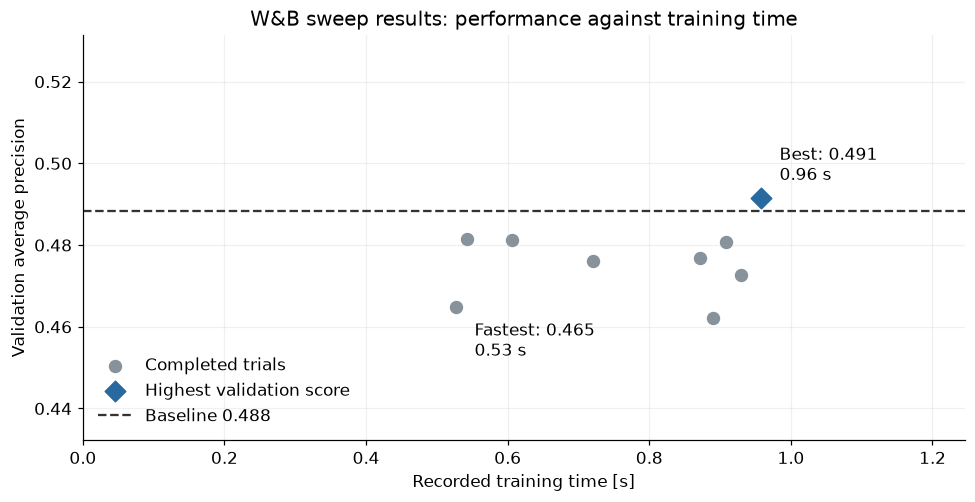

In [15]:
sweep_config = {
    "name": "rf_transparency_v2",
    "method": "bayes",
    "metric": {"name": "val_pr", "goal": "maximize"},
    "parameters": {
        "n_estimators": {"values": [100, 200, 300, 500]},
        "max_depth": {"values": [0, 4, 8, 12, 16]},   # 0 means no limit
        "max_features": {"values": ["sqrt", "log2"]},
        "min_samples_leaf": {"values": [1, 3, 5, 10, 20]},
    },
}
SWEEP_COUNT = 10  # runtime depends on the computer and selected settings

completed_sweep_runs = []

if WANDB_MODE != "online":
    sweep_id = None
    print("Sweeps need WANDB_MODE='online'. Skipped: section 10 uses the baseline settings")
else:
    sweep_id = wandb.sweep(sweep_config, project=WB_PROJECT)
    sweep_trial = partial(
        train_rf_sweep, X_train_t=X_train_t, y_train=y_train,
        X_val_t=X_val_t, y_val=y_val, seed=SEED, start_run=start_run,
    )
    wandb.agent(sweep_id, function=sweep_trial, count=SWEEP_COUNT)
    print(f"Sweep {sweep_id} complete")
    # W&B is now the source of the recorded trial results, read back for this figure
    api = WandbApi()
    sweep_path = f"{WB_ENTITY}/{WB_PROJECT}/{sweep_id}"
    completed_sweep_runs = [r for r in api.sweep(sweep_path).runs
                            if r.state == "finished" and isinstance(r.summary.get("val_pr"), (int, float))
                            and np.isfinite(r.summary["val_pr"])]
    if not completed_sweep_runs:
        raise RuntimeError("No completed sweep runs with a finite val_pr; inspect the sweep before final evaluation")
    sweep_results = sweep_results_frame(completed_sweep_runs)
    fig = plot_sweep_tradeoff(sweep_results, results["random_forest"]["val_pr"])
    plt.show()
    plt.close(fig)

### What the sweep results show

- **Best validation average precision is 0.491**, compared with baseline 0.488: a selected gain of about +0.003
- **The selected forest uses 500 trees, maximum depth 12 and minimum leaf size 3**, with the square-root feature rule at each split
- **The best-scoring trial took about 0.96 s to fit**, compared with 0.53 s for a depth-4 trial scoring 0.465. These recorded times depend on this computer
- **Training remains optimistic:** the selected trial scores 0.991 on training versus 0.491 on validation, a gap of about 0.500

The highest training score does not necessarily mean the best prediction on new patients. The search is small, and its maximum validation score is optimistic because validation guided selection

The 0.044 spread across development splits provides context, not a significance test for the +0.003 gain. Test patients stay outside tuning. Only scored trials belong in this comparison; the final-model entry in the saved sweep list has test results and no `val_pr`

> Judge tuning by validation gain, training cost and model size, while keeping test patients outside selection

Recorded evidence: [saved sweep](https://wandb.ai/idiazl/ml-healthcare-intro/sweeps/4dzr4glh)

The dashed line is the original forest's validation score. The best recorded trial is only slightly above it. Each point is a completed trial, so the plot makes the size of the selected gain and its recorded training cost visible. The W&B sweep workspace can show the same fields interactively


# 10. Save the complete model and evaluate test once

The best completed sweep trial has higher validation average precision than the baseline, so its settings are selected. Preprocessing and the forest are then fitted together on combined training and validation patients

The complete pipeline is evaluated on the same 800 test patients reserved at the start. Test scores do not guide a further model choice

The saved artifact contains the pipeline, settings, library versions and environment file. Two checks test reproducibility: loading the saved file and rebuilding a fresh pipeline from the logged settings

Registry linking is skipped because `REGISTRY_TARGET` is empty. Saving and versioning the model artifact still occurs without a Registry link

**W&B evidence:** model selection uses the same completed validation trials displayed in section 9. The final run then logs test scores and creates a model artifact. Its input-artifact links form the native W&B Lineage graph; the diagram below summarises that record and the reconstruction checks


Best completed sweep val_pr: 0.491; baseline: 0.488
Selected validation gain: +0.003; baseline split SD: 0.044 (context only)
No significance verdict: five overlapping splits and a selected validation maximum cannot establish a tuning benefit
{'test_auc': 0.86, 'test_pr': 0.522, 'test_brier': 0.091, 'test_ece': 0.039}
Test stays: 800; deaths: 111; PR reference: 0.139
Reload max gap 1.1e-16; rebuild max gap 1.1e-16; tolerance 1e-9
Registry skipped: online mode and an explicit collection path are required


On **800** held-out stays, including **111** deaths, the final pipeline has AUROC **0.860** and average precision **0.522**. Its Brier score is **0.091** and ECE is **0.039**. These describe this historical test sample; clinical usefulness needs separate evidence.

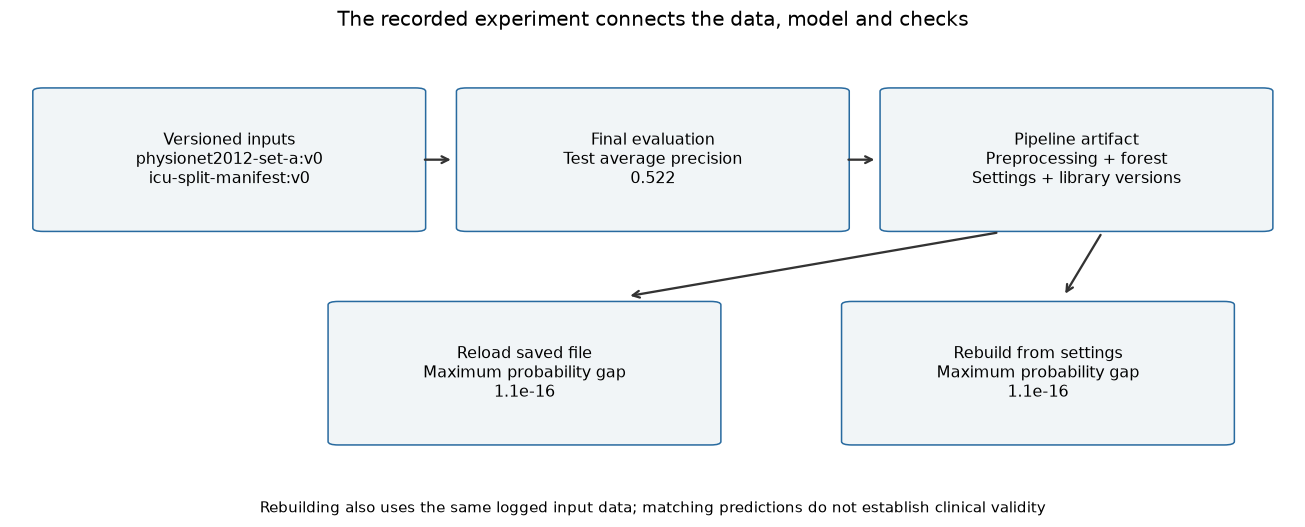

In [16]:
# Select only completed, scored runs from this sweep. API failures stop here rather than silently selecting another model
best_run, rf_params = None, dict(RF_PARAMS)
baseline_pr = results["random_forest"]["val_pr"]
best_val_pr = baseline_pr
if sweep_id:
    # Use the same completed validation trials shown in section 9
    candidate = max(completed_sweep_runs, key=lambda r: r.summary["val_pr"])
    print(f"Best completed sweep val_pr: {candidate.summary['val_pr']:.3f}; baseline: {baseline_pr:.3f}")
    if candidate.summary["val_pr"] > baseline_pr:
        best_run = candidate
        c = best_run.config
        rf_params = {"n_estimators": int(c["n_estimators"]),
                     "max_depth": None if int(c["max_depth"]) == 0 else int(c["max_depth"]),
                     "max_features": c["max_features"], "min_samples_leaf": int(c["min_samples_leaf"])}
        best_val_pr = float(candidate.summary["val_pr"])

gain = best_val_pr - baseline_pr
print(f"Selected validation gain: {gain:+.3f}; baseline split SD: {SPLIT_SD_PR:.3f} (context only)")
print("No significance verdict: five overlapping splits and a selected validation maximum cannot establish a tuning benefit")

final_rf_config = RandomForestClassifier(**rf_params, random_state=SEED, n_jobs=-1).get_params()
run = start_run("08-final-model", "final_eval", config={
    "selected_rf_params": final_rf_config, "selected_val_pr": best_val_pr,
    "tuning_gain_val_pr": gain, "baseline_split_sd_val_pr": SPLIT_SD_PR,
    "source_sweep": sweep_id, "source_run_id": best_run.id if best_run else None,
    "preprocessing": "source -1 codes converted to missing before training medians; most frequent categorical values; one-hot encoding",
}, tags=["final"])

idx_trval = idx_train.append(idx_val)
final_pipeline = Pipeline([("preprocess", make_preprocessor(num_cols, cat_cols)), ("forest", RandomForestClassifier(**final_rf_config))])
final_pipeline.fit(X.loc[idx_trval], y.loc[idx_trval])
y_test_prob = final_pipeline.predict_proba(X.loc[idx_test])[:, 1]
test_metrics = {f"test_{k}": v for k, v in score(y.loc[idx_test], y_test_prob).items()}
wandb.log(test_metrics)
log_curves(y.loc[idx_test], y_test_prob, "test_final")
print({k: round(v, 3) for k, v in test_metrics.items()})
print(f"Test stays: {len(idx_test)}; deaths: {int(y.loc[idx_test].sum())}; PR reference: {y.loc[idx_test].mean():.3f}")

model_file = OUTPUT_DIR / "icu_rf_v2_pipeline.joblib"
joblib.dump(final_pipeline, model_file)
loaded = joblib.load(model_file)
gap_file = float(np.abs(loaded.predict_proba(X.loc[idx_test])[:, 1] - y_test_prob).max())
refit = Pipeline([("preprocess", make_preprocessor(num_cols, cat_cols)),
                  ("forest", RandomForestClassifier(**dict(run.config["selected_rf_params"])))])
refit.fit(X.loc[idx_trval], y.loc[idx_trval])
gap_refit = float(np.abs(refit.predict_proba(X.loc[idx_test])[:, 1] - y_test_prob).max())
np.testing.assert_allclose(loaded.predict_proba(X.loc[idx_test])[:, 1], y_test_prob, atol=1e-9, rtol=0)
assert gap_refit < 1e-9, "Rebuilt predictions differ; check data, preprocessing, settings and versions"
wandb.log({"repro_saved_file_max_gap": gap_file, "repro_refit_max_gap": gap_refit,
           "repro_saved_file_ok": gap_file < 1e-9, "repro_refit_from_config_ok": gap_refit < 1e-9})
print(f"Reload max gap {gap_file:.1e}; rebuild max gap {gap_refit:.1e}; tolerance 1e-9")

settings_file = OUTPUT_DIR / "icu_rf_v2_settings.json"
settings_file.write_text(json.dumps(dict(run.config), indent=2), encoding="utf-8")
versions_file = OUTPUT_DIR / "requirements-run.txt"
versions_file.write_text("\n".join(f"{p}=={v}" for p, v in VERSIONS.items()) + "\n", encoding="utf-8")
model_at = wandb.Artifact("icu-rf-v2-pipeline", type="model",
    description="Teaching pipeline: predict hospital death after the first 48 h of an ICU stay",
    metadata={"forest_params": final_rf_config, **test_metrics, "trained_on": "train + validation",
              "split_seed": SEED, "environment": ENVIRONMENT, "input_versions": INPUT_REFS,
              "dataset_sha256": DATA_SHA256, "split_sha256": SPLIT_SHA256,
              "prediction_time": "after 48 h in ICU", "intended_use": "Teaching only",
              "known_limits": "Historical research cohort; excludes stays shorter than 48 h; no external or clinical validation",
              "selected_by": "validation average precision" if best_run else "baseline settings",
              "repro_saved_file_max_gap": gap_file, "repro_refit_max_gap": gap_refit})
for file in [model_file, settings_file, versions_file, Path("environment.yml")]:
    model_at.add_file(str(file))
logged_model = run.log_artifact(model_at, aliases=["teaching_candidate"])
if WANDB_MODE == "online" and REGISTRY_TARGET:
    logged_model.wait()
    run.link_artifact(logged_model, REGISTRY_TARGET, aliases=["staging"])
    print("Registry link requested:", REGISTRY_TARGET)
else:
    print("Registry skipped: online mode and an explicit collection path are required")
display(Markdown(f"On **{len(idx_test)}** held-out stays, including **{int(y.loc[idx_test].sum())}** deaths, "
                 f"the final pipeline has AUROC **{test_metrics['test_auc']:.3f}** and average precision "
                 f"**{test_metrics['test_pr']:.3f}**. Its Brier score is **{test_metrics['test_brier']:.3f}** "
                 f"and ECE is **{test_metrics['test_ece']:.3f}**. "
                 "These describe this historical test sample; clinical usefulness needs separate evidence."))
log_fig("reproducibility_chain", plot_reproducibility_chain(INPUT_REFS, test_metrics, gap_file, gap_refit), tight=False)
run.finish()


### What the final results show

- **Test ranking area:** 0.860
- **Test average precision:** 0.522, compared with a death-fraction reference of 0.139
- **Probability checks:** Brier error 0.091 and expected calibration error 0.039
- **Evaluation population:** 800 reserved stays, including 111 deaths
- **Reconstruction:** reload and rebuild gaps are about 1.1e-16 each, within the 1e-9 tolerance

Both reproducibility checks pass. Artifact `icu-rf-v2-pipeline` holds preprocessing and forest together. Its lineage connects the model to raw-data and patient-split artifacts

Higher test average precision than validation does not establish that refitting improved performance: the patient samples differ. These results describe one historical held-out sample; clinical usefulness and external validity remain unresolved

Rebuilding succeeds in this environment with these data. It does not guarantee identical predictions across software versions. Earlier SHAP results concern the baseline forest, not this final refit

> Save preprocessing with the model and verify that reloading and rebuilding preserve its predictions

W&B references: [sweep API source](https://github.com/wandb/wandb/blob/main/wandb/apis/public/sweeps.py), [artifact and Registry API source](https://github.com/wandb/wandb/blob/main/wandb/sdk/wandb_run.py)


# 11. The story in one view

**The comparison:** the forest leads logistic regression on this validation split and on all five shared development splits, but the margin varies. The small selected tuning gain does not establish a general improvement

**The explanation:** averaging tree probabilities explains the forest calculation, and SHAP contributions explain individual predictions. The shuffled-outcome check shows why a convincing ranking can coexist with weak prediction

**The experiment record:** W&B holds the settings, metrics, versioned inputs, explanations and final pipeline. It allows a result to be traced to the experiment that produced it. Reloading and rebuilding recover the final predictions in this environment

Together, the figures and record explain what was done and what was observed. Clinical usefulness, external validity and causal explanations remain unresolved. The baseline explanations and final test results concern different fitted models

> Use the experiment record to connect performance, explanation and reconstruction before drawing conclusions about model usefulness


# 12. Key takeaways

- Record data versions, patient splits, settings and code so each result has a traceable source
- Compare models on shared development splits and reserve test patients for final evaluation
- Follow tree probabilities and their average to understand a forest prediction
- Check contribution sums and held-out performance before trusting an explanation or feature ranking
- Save the complete pipeline and verify that reloading and rebuilding reproduce its predictions
